In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.signal import hilbert

import tinyDA as tda
import umbridge

/home/dubois/miniconda3/envs/umbridge/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-23 16:28:06,351	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


# Generate sythetic data

## Read saved datas

In [2]:
# Instead of running umbridge: open the savef d_true
with open('d_true.npy', 'rb') as f:
    d_true = np.load(f)
ny = len(d_true)

n_sensors = 2

## Generate new synthetic data
If you want to change something in the pysical setup (e.g. sensors location), you need to rerun this part together with the terra DG server.

In [2]:
# Set all simu parameters 
# Set domain size and simulation time: this info is shared between the forward and parameter models 
Lx = 20
Lz = 1 
TEnd = 10 
H = 1.5


# Create the config data
#### Change captor location and number
# Each element of the list "captors" is a tuple of (x,z) coordinates. 
# Coordinates are given in the (scaled) domain: x \in [0, grid_size_x], z \in [0, grid_size_y]
sensors = [(4,0.8), (13.5, 0.6)]
# sensors = [(2,0.), (0, 1)]

# Create sorted sensor list to pass to the forward model: do not change this part 
sensors_sort = np.array(sensors, dtype=[('x',float),('y',float)])
sensors_sort = np.sort(sensors_sort, order=['x','y'])
sensors = sensors_sort.tolist()
n_sensors = len(sensors)
print("Number of pressure sensors:", n_sensors)

# connect to the UM-Bridge model.
umbridge_model = umbridge.HTTPModel('http://localhost:4242', "forward")

# wrap the UM-Bridge model in the tinyDA UM-Bridge interface.
config={"captors":sensors}
my_model = tda.UmBridgeModel(umbridge_model, umbridge_config=config)

Number of pressure sensors: 2


In [3]:
# Informations relative to the parameter model
# Set in the jl server: 
# - number of points to describe the level set passed to the forward model = nx
# - number of points to describe all pressure time series given by the forward model = ny
nx = umbridge_model.get_input_sizes(config)[0] #the input is the value of f(x) at each grid point
ny = umbridge_model.get_output_sizes(config)[0] #the outout is a time series of the pressure

print(f"input:{nx}, output:{ny}")

input:60, output:202


In [ ]:
# Generate synthetic data
exact = np.zeros(nx)

# True source in the middle of the domain 
idx_middle = int(nx/2)
source_width = 4 # in length unit 
idx_width = int(0.5 * source_width / Lx * nx )
exact[idx_middle - idx_width : idx_middle + idx_width]=1
d_true = my_model(exact)

# add some noise to the model output
# d = d_true + np.random.normal(loc=0, scale=sigma_noise, size=ny)

KeyboardInterrupt: 

In [ ]:
# Save the new data
with open('d_true.npy', 'wb') as f:
    np.save(f, d_true)


## Show pressure outputs
plt.plot(d_true[0::n_sensors])
plt.show()
plt.plot(d_true[1::n_sensors])

# Set up log-likelihood

Test standard Gaussian log-likelihood:
$$\log ⁡L(x)=-0.5(x-y)^T\Sigma^{-1}(x−y)$$

with a Wasserstein-2-based log-likelihood as in Dunlop+Yang, 2021:
$$\log ⁡L(x)\propto -\lambda W_2(x,y),$$

where:
- x = model output
- y = ground truth

with an applied scaling $\sigma(x)$

While $W_1$ is contained in scipy.stats it seems $W_2$ is not

In [3]:
def sigma_linear(v, b):
    return v + b

def sigma_signsensitive(v, b):
    pos = v >= 0
    raw = np.empty_like(v)
    raw[pos] = v[pos] + 1.0 / b
    raw[~pos] = (1.0 / b) * np.exp(b * v[~pos])
    return raw

def sigma_softplus(v, b):
    return np.logaddexp(0.0, b * v)

def sigma_envelope_exp(v, b):
    env = np.abs(hilbert(v))
    return np.exp(b * env)

class WassersteinLoglike:
    """Wasserstein log-likelihood.
    `sigma` is a scaling function"""

    def __init__(self, data, sigma, lam=1.0, b=1.0, n_quantiles=200):
        self.data = np.asarray(data, dtype=float).ravel()
        self.sigma = sigma
        self.lam = lam
        self.b = b
        self.n_quantiles = n_quantiles

    def _density(self, x):
        raw = self.sigma(x, self.b)
        return raw / raw.sum()

    def _quantile_function(self, density):
        cdf = np.cumsum(density); cdf = cdf / cdf[-1]
        t = np.arange(len(density), dtype=float)
        u = (np.arange(self.n_quantiles) + 0.5) / self.n_quantiles
        return np.interp(u, cdf, t)

    def loglike(self, x):
        x = np.asarray(x, dtype=float).ravel()
        p, q = self._density(x), self._density(self.data)
        Fx, Fd = self._quantile_function(p), self._quantile_function(q)
        return -self.lam * np.sum((Fx - Fd) ** 2) / self.n_quantiles

class MultiSensorLoglike:
    """likelihoods: a list of length n_sensors likelihoods, each already
    constructed with its own sensor's reference data."""
    def __init__(self, likelihoods, n_sensors):
        self.likelihoods = likelihoods
        self.n_sensors = n_sensors

    def loglike(self, x):
        x = np.asarray(x, dtype=float).ravel()   # <- use the argument, not a stored copy
        return sum(like.loglike(x[i::self.n_sensors]) for i, like in enumerate(self.likelihoods)) 


In [4]:
# Define the "forward map" for the 1D model: shift the pressure recordings. 
# Note that the shift is an integer value, to avoid interpolation. 

def shift_per_sensor(flat_signal, shift, n_sensors):
    flat_signal = np.asarray(flat_signal, dtype=float).ravel()
    parts = [np.roll(flat_signal[i::n_sensors], shift) for i in range(n_sensors)]
    out = np.empty_like(flat_signal)
    for i, p in enumerate(parts):
        out[i::n_sensors] = p
    return out

In [ ]:
## Shows the loss (=-loglike) for some values of b
## Those are NOT the scaling used for the plots in the next cells. The values of b and lambda will be different.
# Test for Gaussian log like
sigma = 2.0
cov_likelihood = sigma**2*np.eye(d_true.shape[0])
my_loglike_gaussian = tda.GaussianLogLike(d_true, cov_likelihood)

# Test for Wasserstain based log like
# TODO move implementation into tinyDA
sigma_noise = 0.01
lam = sigma_noise * sigma_noise
# sign_sensitive scaling
my_loglike = MultiSensorLoglike(likelihoods=[
    WassersteinLoglike(d_true[0::n_sensors], sigma_signsensitive, lam=lam, b=100.0),    # b standard value:100
    WassersteinLoglike(d_true[1::n_sensors], sigma_signsensitive, lam=lam, b=1.0),    # b standard value:1
], n_sensors=2)

# linear scaling
my_loglike_linear = MultiSensorLoglike(likelihoods=[
    WassersteinLoglike(d_true[0::n_sensors], sigma_linear, lam=lam, b=0.1), # b standard value:0.1
    WassersteinLoglike(d_true[1::n_sensors], sigma_linear, lam=lam, b=1.1), # b standard value:1.1
], n_sensors=2)

# hilbert envelop scaling
my_loglike_envelope = MultiSensorLoglike(likelihoods=[
    WassersteinLoglike(d_true[0::n_sensors], sigma_envelope_exp, lam=lam, b=15.0),   # b standard value:15
    WassersteinLoglike(d_true[1::n_sensors], sigma_envelope_exp, lam=lam, b=5.0),    # b standard value:5
], n_sensors=2)


likelihoods = {
    "Gaussian": my_loglike_gaussian,
    "Sign-sensitive": my_loglike,
    "Linear": my_loglike_linear,
    "Envelope": my_loglike_envelope,
}

shifts = np.arange(-30, 31)
fig, ax = plt.subplots(figsize=(9, 5))
for name, like in likelihoods.items():
    vals = np.array([-like.loglike(shift_per_sensor(d_true, s, n_sensors)) for s in shifts])
    ax.plot(shifts, vals / (vals.max() or 1), label=name, marker='.')
ax.axvline(0, color='k', ls=':', lw=1)
ax.set_xlabel("shift (samples)")
ax.set_ylabel("normalized cost (0=best fit)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for name, like in likelihoods.items():
    vals = np.array([like.loglike(shift_per_sensor(d_true, s, n_sensors)) for s in shifts])
    ax.plot(shifts, np.exp(vals), label=name, marker='.')
ax.axvline(0, color='k', ls=':', lw=1)
ax.set_xlabel("shift (samples)")
ax.set_ylabel("exp(loglike) ")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Computing the marginals 

In [ ]:
# Integration using Simpson integration 
from scipy.integrate import simpson

# Number of integration samples: 61
shifts = np.arange(-30,31)

# Integration routine 
def marginal_likelihood(sigma, lam, b, d_):
    # Possible sigma:
    # sigma_linear
    # sigma_signsensitive
    # sigma_softplus
    # sigma_envelope_exp

    my_loglike = MultiSensorLoglike(likelihoods=[
        WassersteinLoglike(d_[0::n_sensors], sigma, lam=lam, b=b),
        WassersteinLoglike(d_[1::n_sensors], sigma, lam=lam, b=b),
    ], n_sensors=n_sensors)
    vals = np.array([my_loglike.loglike(shift_per_sensor(d_, s, n_sensors)) for s in shifts]) 
    exp_vals = np.exp(vals)
    return simpson(exp_vals, shifts)


sigmas = {
    "Linear": sigma_linear,
    "Sign-sensitive": sigma_signsensitive,
    "sigma_softplus": sigma_softplus,
    "Envelope": sigma_envelope_exp,
}

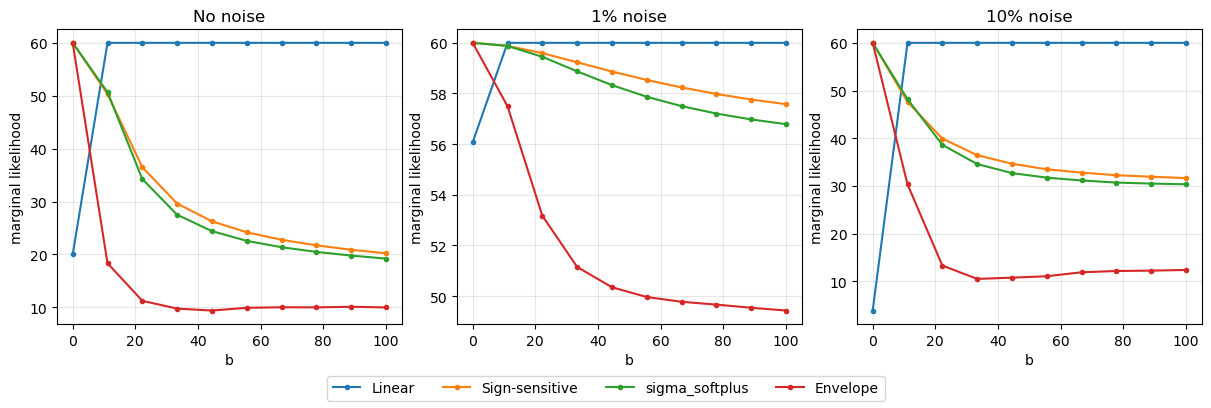

In [16]:
# Plot the marginals as function of b with various noise levels
fig, ax = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
array_b = np.linspace(0.01, 100, 10)


### Marginals for the sythetic signal with no noise as reference
lam = 0.01 
for name, scaling in sigmas.items():
    margs = [marginal_likelihood(scaling, lam, b, d_true) for b in array_b]
    ax[0].plot(array_b, margs,  marker='.')
    ax[0].set_title("No noise")


# Marginals for the sythetic signal with 1% noise
sigma_noise = 0.01
lam = sigma_noise**2 
d = d_true + np.random.normal(loc=0, scale=sigma_noise, size=ny)
for name, scaling in sigmas.items():
    margs = [marginal_likelihood(scaling, lam, b, d) for b in array_b]
    ax[1].plot(array_b, margs,marker='.')
    ax[1].set_title("1% noise")


# Marginals for the sythetic signal with 1% noise
sigma_noise = 0.1
lam = sigma_noise**2 
d = d_true + np.random.normal(loc=0, scale=sigma_noise, size=ny)
for name, scaling in sigmas.items():
    margs = [marginal_likelihood(scaling, lam, b, d) for b in array_b]
    ax[2].plot(array_b, margs, label=name, marker='.')
    ax[2].set_title("10% noise")



for ax_ in ax:
    ax_.set_xlabel("b")
    ax_.set_ylabel("marginal likelihood")
    ax_.grid(alpha=0.3)
fig.legend(loc="outside lower center", ncols = 4)